# Nonlinear coefficients of GP2–GP4 from a composition network (Section 3)

No LAOS data exist for GP2–GP4, so $c_3$–$c_6$ of eq. (9) are predicted by a small neural network
trained on the 18 identified coefficient sets of GP1 (Table 4) and GP5 (Table 5). Inputs: critical
stress, critical time, Si and H₂O ratios (Al = Na = 1 for every composition) and sample age.
In the nonlinear branch $c_1$, $c_2$ are taken equal to the linear-regime values (`08c`) and $c_7 = 0$.

The network is then evaluated over the 3ITT protocol (ages 0–750 s), i.e. well below the training
ages (GP1: 60–540 min, GP5: 6–76 min).

* **Inputs:** `results/coefficients/GP*_LAOS_*.csv`, `results/critical_points.csv`
* **Outputs:** `results/other_gps/GP{2,3,4}_LAOS_network.csv`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rhinn_sindy import data
from rhinn_sindy.coefficient_network import OUTPUTS, CoefficientNetwork, training_table
from rhinn_sindy.paths import RESULTS_DIR

OUT_DIR = RESULTS_DIR / "other_gps"
OUT_DIR.mkdir(parents=True, exist_ok=True)
TARGETS = ["GP2", "GP3", "GP4"]
T_GRID = np.arange(0.0, 751.0, 1.0)   # s, covers the simulated 3ITT protocol

## Training data (Tables 4 and 5)

The network of Fig. 10 was trained on hand-entered coefficients: rounded (1–3 significant figures),
including the early-age $c_3$, $c_4$ of both materials that Tables 4–5 set to zero, and with GP5
$c_3$ at 6 min entered as 4.2e-7 (identified 4.39e-7). Training is deterministic, and these targets
reproduce the published network exactly. `REPRODUCE_PAPER = False` trains on Tables 4–5
(`results/coefficients`) instead.

In [2]:
REPRODUCE_PAPER = True

# Columns c3..c6; rows in the order of training_table (GP1 1-9 h, then GP5 6-76 min).
PRINTED_TARGETS = np.array([
    [5.8e-5, 0.0012, 0.00074, -0.00052], [0, 0, 0.00076, 0], [0, 0, 0.0008, 0],
    [0, 0, 0.0006, 0], [0, 0, 0.0005, 0], [0, 0, 0.0003, 0.00012],
    [0, 0, 0.0002, 1.8e-5], [0, 0, 5.42e-5, 0.00016], [0, 0, 0, 4e-5],
    [4.2e-7, 2.92e-6, 1.44e-7, 0], [3.4e-7, 4.06e-6, 0, 0], [0, 0, 1.82e-7, 0],
    [0, 0, 5.8e-7, 0], [0, 0, 2.7e-7, 0], [0, 0, 1.61e-7, 0],
    [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0],
])

critical = pd.read_csv(RESULTS_DIR / "critical_points.csv", index_col="material")
table = training_table(critical)
if REPRODUCE_PAPER:
    table[OUTPUTS] = PRINTED_TARGETS
table

,material,sigma_cr,t_cr_min,Si,H2O,age_min,c3,c4,c5,c6
0,GP1,0.5,11.957,2.0,5.0,60.0,5.800000e-05,0.001200,7.400000e-04,-0.000520
1,GP1,0.5,11.957,2.0,5.0,120.0,0.000000e+00,0.000000,7.600000e-04,0.000000
2,GP1,0.5,11.957,2.0,5.0,180.0,0.000000e+00,0.000000,8.000000e-04,0.000000
3,GP1,0.5,11.957,2.0,5.0,240.0,0.000000e+00,0.000000,6.000000e-04,0.000000
4,GP1,0.5,11.957,2.0,5.0,300.0,0.000000e+00,0.000000,5.000000e-04,0.000000
5,GP1,0.5,11.957,2.0,5.0,360.0,0.000000e+00,0.000000,3.000000e-04,0.000120
6,GP1,0.5,11.957,2.0,5.0,420.0,0.000000e+00,0.000000,2.000000e-04,0.000018
7,GP1,0.5,11.957,2.0,5.0,480.0,0.000000e+00,0.000000,5.420000e-05,0.000160
8,GP1,0.5,11.957,2.0,5.0,540.0,0.000000e+00,0.000000,0.000000e+00,0.000040
9,GP5,200.0,9.792,1.3,5.5,6.0,4.200000e-07,0.000003,1.440000e-07,0.000000


## Train

2026-11-02 19:24:09.017247: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


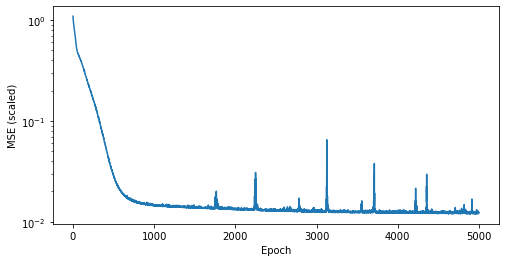

In [3]:
net = CoefficientNetwork(seed=42)
history = net.fit(table)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history.history["loss"])
ax.set(yscale="log", xlabel="Epoch", ylabel="MSE (scaled)")
plt.show()

## Predict along the 3ITT protocol

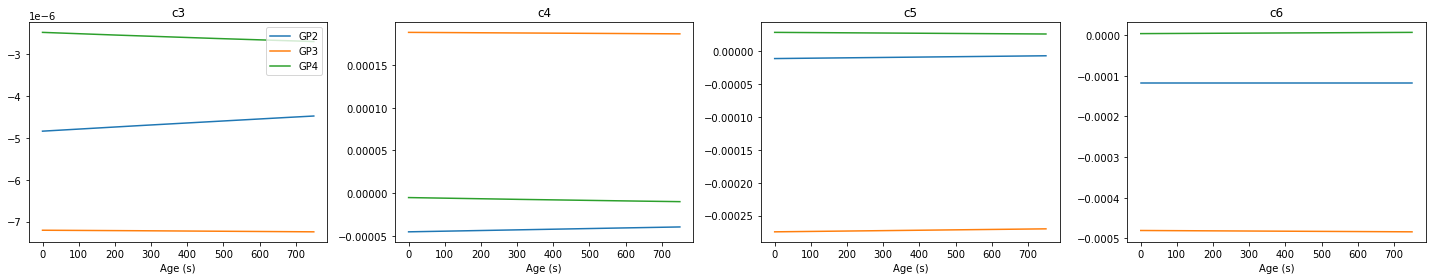

In [4]:
for gp in TARGETS:
    pred = net.predict(critical.loc[gp, "sigma_cr"], critical.loc[gp, "t_cr"],
                       data.COMPOSITIONS[gp], T_GRID / 60.0)
    pred.insert(0, "t_s", T_GRID)
    pred.to_csv(OUT_DIR / f"{gp}_LAOS_network.csv", index=False, float_format="%.8g")

fig, axes = plt.subplots(1, len(OUTPUTS), figsize=(20, 4))
for ax, c in zip(axes, OUTPUTS):
    for gp in TARGETS:
        ax.plot(T_GRID, pd.read_csv(OUT_DIR / f"{gp}_LAOS_network.csv")[c], label=gp)
    ax.set(title=c, xlabel="Age (s)")
axes[0].legend()
fig.tight_layout()
plt.show()